## Fitting the transfer function of a neuron with N synaptic channels

#### Ilaria Carannante
mailto: ilariac@kth.se
###### KTH, Stockholm, Sweden
###### NeuroPSI, ICN, Saclay, France

In this notebook we fit the transfer function of an AdEx neuron with N synaptic channels (here 4). The data was obtained running *TF_data_extraction_neuron_4_inputs.py* in the *data_extraction* folder.

The fitting procedure is the same as for the RS and FS neurons (*TF_fitting_RS.ipynb*). Only the computation of the membrane potential fluctuations ($\mu_V$, $\sigma_V$, $\tau_V$) changes: the sums run over the N channels, each with its own $E_s$, $Q_s$, $\tau_s$ and $K_s$. The routing is automatic: `membrane_potential_fluctuations` and `TF_template` switch to the N-channel version when the parameter dictionary has a `channels` block.

In [1]:
#%matplotlib widget
import matplotlib.pyplot as plt

In [2]:
import sys
import os
import json

# Adding the project folder to sys.path
cwd = os.getcwd()
parent_dir = os.path.abspath(os.path.join(cwd, '..', '..',))
sys.path.append(parent_dir)
# We do this so that we can directly import files in the utils folder

In [3]:
from utils.Plots_helper import *
from ntmf.transfer_function import *
from ntmf.optimization import run_fits, discrete_alpha_search
from ntmf.config import get_params_model_SI_general, adding_K_params_general
from scipy.optimize import minimize

In [4]:
# Setting file saving
figs = []
fig_path = os.path.join('figures')
isExist = os.path.exists(fig_path)
if not isExist:
   os.makedirs(fig_path)
   print('The directory "figures" is created.')

def save_figs(fig_path, name, figs):
    pdf_file_path = os.path.join(fig_path, name + '-figs.pdf')
    with PdfPages(pdf_file_path) as ofile:
        for fig in figs:
            ofile.savefig(fig) 

In [5]:
results_path = os.path.join('results')
isExist = os.path.exists(results_path)
if not isExist:
   os.makedirs(results_path)
   print('The directory "results" is created.')

In [6]:
neuron_model = 'neuron_4_inputs'

In [7]:
fig_name = f'TF_fitting_{neuron_model}'
saving_json = False
out_file_name = f'results_{neuron_model}.json'
# if opt_alpha is set to False and the file alpha_results_<folder>.json
# does not exist, then alpha is set to 1
opt_alpha = True

# Background input: the extraction script drives some channels with a constant background
# (independent Poisson group, same N_external and conn_prob). If True, its rate is added to
# the swept rate of that channel when computing mu_V, sig_V, tau_V.
# The RS/FS fits ignored it (equivalent to False).
include_background = True

# to save and display the gif, set the following to true
display_gif = False
gif_name = os.path.join('..', '..', 'GIF_folder', f'TF_fitting_{neuron_model}.gif')

## Setting up the neuron model

In [8]:
data_folder = '../../neuron_models/AdEx'
idx = 0 # in this case only one model per cell type is provided

In [9]:
params_SI = get_params_model_SI_general(json_file_name = os.path.join(data_folder, neuron_model + '.json'),
                                        idx = idx)

## Reading in the data and the extraction metadata
The number of inputs per channel, $K_s$ = N_external$_s$ × conn_prob$_s$, and the background rates are read from the `_meta.json` written by the extraction script, so the fit uses the connectivity the data were simulated with.

In [10]:
simulation_folder = f'../data_extraction/simulations/TF_{neuron_model}_delay_v2'

In [11]:
# --- Load the data ---
df_data = pd.read_csv(
    os.path.join(simulation_folder, f'TF_data_{neuron_model}.dat'),
    sep=r'\s+',
    header = 0
)

# --- Load the metadata ---
with open(os.path.join(simulation_folder, f'TF_data_{neuron_model}_meta.json'), 'r') as fh:
    meta = json.load(fh)

In [12]:
params_SI = adding_K_params_general(neuron_params = params_SI,
                                    tf_meta = meta,
                                    include_background = include_background)

In [13]:
channels = list(params_SI['channels'])
ch_info = tf_channel_info(meta)
for k in channels:
    c = params_SI['channels'][k]
    print(f"{ch_info[k]['short']}: E = {1e3 * c['E']:g} mV, Q = {1e9 * c['Q']:g} nS, tau = {1e3 * c['tau']:g} ms, "
          f"K = {c['K']:g}, background = {c['nu_bg']:g} Hz")

ch 1 (exc): E = 0 mV, Q = 1.5 nS, tau = 3 ms, K = 300, background = 1 Hz
ch 2 (inh): E = -80 mV, Q = 5 nS, tau = 5 ms, K = 100, background = 0 Hz
ch 3 (inh): E = -80 mV, Q = 1 nS, tau = 7 ms, K = 70, background = 0 Hz
ch 4 (exc): E = 0 mV, Q = 2.5 nS, tau = 7 ms, K = 30, background = 0 Hz


In [14]:
grid_vals, is_grid = tf_grid_values(df_data, channels)
print(f'Number of input points: {len(df_data)} -- full grid: {is_grid}')
for k in channels:
    print(f'  ch {k}: {grid_vals[k].tolist()}')

Number of input points: 256 -- full grid: True
  ch 1: [0, 10, 20, 30]
  ch 2: [0, 10, 20, 30]
  ch 3: [0, 10, 20, 30]
  ch 4: [0, 10, 20, 30]


### Choosing the slice used for the 2D plots
Plots inherited from the RS/FS notebooks show a 2D slice: the main excitatory channel on the x axis, the main inhibitory channel on the y axis (largest $K$), and the other channels fixed at `fixed`. Change `fixed` to inspect other slices.

In [15]:
exc_chs = [k for k in channels if ch_info[k]['kind'] == 'exc']
inh_chs = [k for k in channels if ch_info[k]['kind'] == 'inh']
x_ch = max(exc_chs, key=lambda k: params_SI['channels'][k]['K'])
y_ch = max(inh_chs, key=lambda k: params_SI['channels'][k]['K'])
others = [k for k in channels if k not in (x_ch, y_ch)]

fixed = {k: float(grid_vals[k][0]) for k in others}   # lowest value on the other channels
slice_suffix = ' | ' + ', '.join(f'ch {k} = {v:g} Hz' for k, v in fixed.items())
print(f'x: ch {x_ch}, y: ch {y_ch}, fixed: {fixed}')

x: ch 1, y: ch 2, fixed: {'3': 0.0, '4': 0.0}


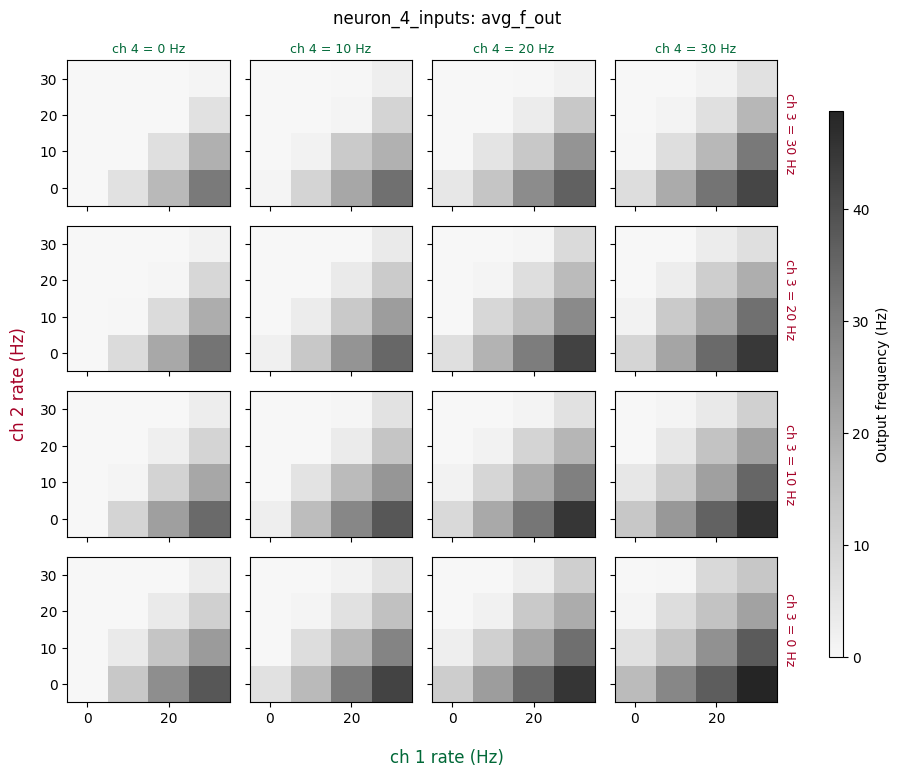

In [16]:
fig = plot_TF_slice_grid(df_data, ch_info, neuron_model=neuron_model,
                         x_ch=x_ch, y_ch=y_ch,
                         row_ch=others[0] if len(others) > 0 else None,
                         col_ch=others[1] if len(others) > 1 else None,
                         fixed={k: fixed[k] for k in others[2:]})
figs.append(fig)

## Computing membrane potential fluctuations

In [17]:
mu_V, sig_V, tau_V, tau_V_norm = membrane_potential_fluctuations(data = df_data, params = params_SI)

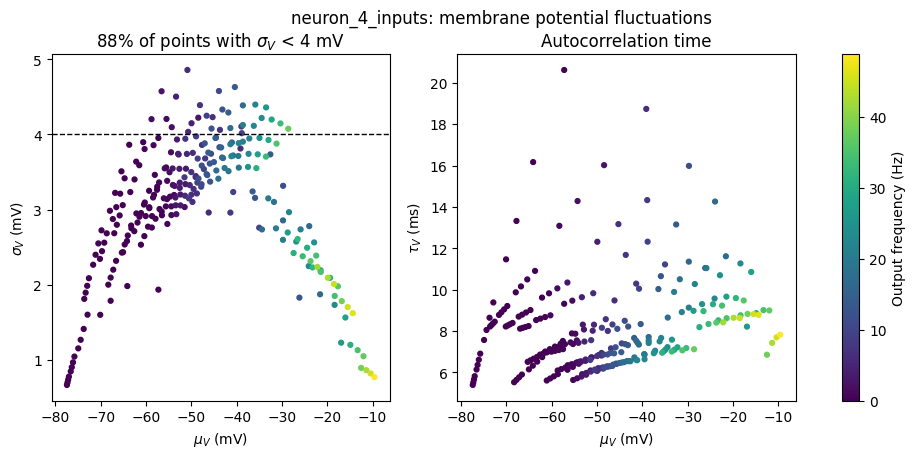

In [18]:
fig = plot_membrane_fluctuations_overview(df_data, mu_V, sig_V, tau_V, neuron_model=neuron_model)
figs.append(fig)

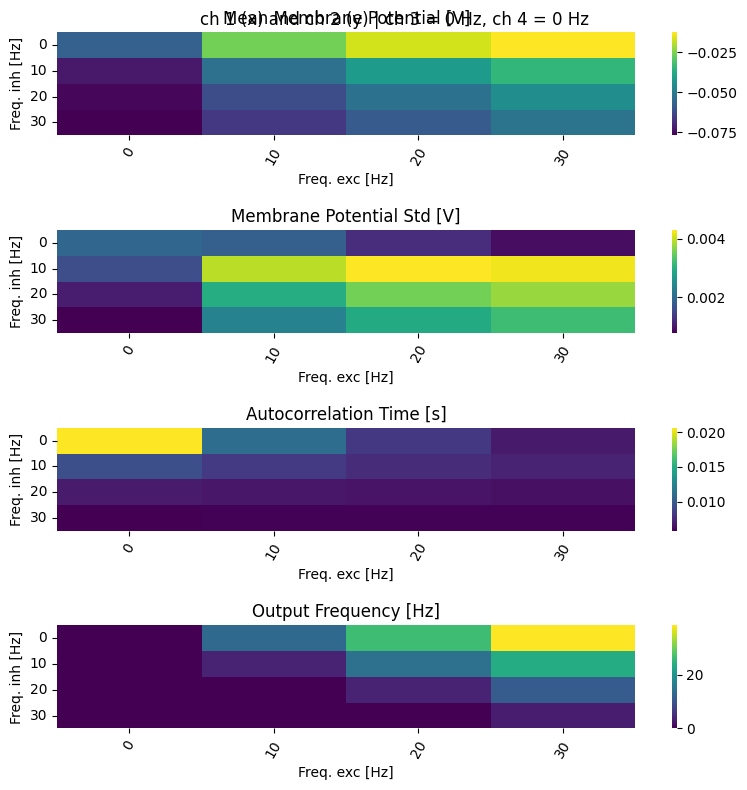

In [19]:
# Same 4-panel plot as for RS/FS, on the 2D slice
df_slice = tf_slice_as_ei(df_data, x_ch, y_ch, fixed)
mu_V_s, sig_V_s, tau_V_s, _ = membrane_potential_fluctuations(data = df_slice, params = params_SI)
fig = plot_membrane_potential_fluctuations(data = df_slice, mu_V = mu_V_s, sig_V = sig_V_s, tau_V = tau_V_s)
fig.suptitle(f'ch {x_ch} (x) and ch {y_ch} (y){slice_suffix}')
figs.append(fig)

## Optimizing alpha value to guide its selection

In [20]:
folder_name = os.path.basename(simulation_folder)
if opt_alpha == True:
    best_alpha, best_error, best_poly = discrete_alpha_search(
         df_data = df_data,
         mu_V = mu_V,
         sig_V = sig_V,
         tau_V = tau_V,
         tau_V_norm = tau_V_norm,
         params_SI = params_SI,
         alpha_min=0.1, alpha_max=2.0, alpha_step=0.001,
         saving_json=True,
         out_file_name = os.path.join ('results', f'alpha_results_{folder_name}.json'))

WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 86 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]
WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 85 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]


Tested alpha: 0.100, mean_error: 91.927443
Tested alpha: 0.101, mean_error: 90.783021
Tested alpha: 0.102, mean_error: 90.002027
Tested alpha: 0.103, mean_error: 88.659219
Tested alpha: 0.104, mean_error: 87.771914
Tested alpha: 0.105, mean_error: 86.693802
Tested alpha: 0.106, mean_error: 85.639160


WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 83 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]


Tested alpha: 0.107, mean_error: 84.678206
Tested alpha: 0.108, mean_error: 83.691419
Tested alpha: 0.109, mean_error: 82.682936
Tested alpha: 0.110, mean_error: 81.758747


WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 82 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]


Tested alpha: 0.111, mean_error: 80.841363
Tested alpha: 0.112, mean_error: 79.770388


... (124 outputs left out)

WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 2 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]


Tested alpha: 0.384, mean_error: 2.671908
Tested alpha: 0.385, mean_error: 7.875120
Tested alpha: 0.386, mean_error: 7.556529
Tested alpha: 0.387, mean_error: 12.208436
Tested alpha: 0.388, mean_error: 4.725868
Tested alpha: 0.389, mean_error: 6.494395
Tested alpha: 0.390, mean_error: 7.512405
Tested alpha: 0.391, mean_error: 7.041954
Tested alpha: 0.392, mean_error: 8.015995
Tested alpha: 0.393, mean_error: 10.194632
Tested alpha: 0.394, mean_error: 6.510099
Tested alpha: 0.395, mean_error: 11.993096
Tested alpha: 0.396, mean_error: 6.025226


WARNING    /home/ilariac/Documents/GitHub/working_on/neuron-to-meanfield/ntmf/optimization.py:67: UserWarning: est_thresh: 1 element(s) of 'arg' outside (0, 2). They will be clipped for erfcinv.
  est_V_th = est_thresh(data=df_data, mu_V=mu_V, sig_V=sig_V, tau_V=tau_V, alpha=alpha)
 [py.warnings]


Tested alpha: 0.397, mean_error: 6.322508
Tested alpha: 0.398, mean_error: 8.186090
Tested alpha: 0.399, mean_error: 8.116645
Tested alpha: 0.400, mean_error: 8.565021
Tested alpha: 0.401, mean_error: 10.692060
Tested alpha: 0.402, mean_error: 11.986732
Tested alpha: 0.403, mean_error: 12.684813
Tested alpha: 0.404, mean_error: 9.135822
Tested alpha: 0.405, mean_error: 7.691830
Tested alpha: 0.406, mean_error: 7.579002
Tested alpha: 0.407, mean_error: 8.591995
Tested alpha: 0.408, mean_error: 9.095930
Tested alpha: 0.409, mean_error: 9.546496
Tested alpha: 0.410, mean_error: 9.845235
Tested alpha: 0.411, mean_error: 14.593671
Tested alpha: 0.412, mean_error: 6.328266
Tested alpha: 0.413, mean_error: 12.292554
Tested alpha: 0.414, mean_error: 11.478787
Tested alpha: 0.415, mean_error: 8.428494
Tested alpha: 0.416, mean_error: 9.282317
Tested alpha: 0.417, mean_error: 9.068549
Tested alpha: 0.418, mean_error: 10.260711
Tested alpha: 0.419, mean_error: 12.409170
Tested alpha: 0.420, mean_

## TF (re)fitting with selected alpha(s) 

In [21]:
alpha_out_file_name = os.path.join ('results', f'alpha_results_{folder_name}.json')

In [22]:
if os.path.exists(alpha_out_file_name): 
    with open (alpha_out_file_name, 'r') as f:
        alpha_data = json.load(f)
        # Extract arrays
        alphas = np.array([entry['alpha'] for entry in alpha_data])
        mean_errors = np.array([entry['mean_error'] for entry in alpha_data])
        
        # Get indices of the mean errors
        sorted_indices = np.argsort(mean_errors)
        
        # Sort both arrays using those indices
        sorted_mean_errors = mean_errors[sorted_indices]
        sorted_alphas = alphas[sorted_indices]
        
        # Example: get the n smallest mean_errors and their alphas
        n = 10
        print(f'Smallest {n} mean errors: {sorted_mean_errors[:n]}')
        print(f'Corresponding alphas: {sorted_alphas[:n]}')

        alpha = sorted_alphas[0]
else:
        alpha = 1    

Smallest 10 mean errors: [2.19264548 2.30606878 2.37136996 2.44003114 2.44203612 2.62866889
 2.67190821 2.74665442 2.74929362 2.77933503]
Corresponding alphas: [0.679 0.82  0.785 0.853 1.701 0.775 0.384 1.194 0.351 0.768]


### Saving the 10 best fits (ordered by mean error)


In [23]:
# Save the 10 best fits (alpha, mean_error, polynomial_params), already ordered,
# to a dedicated file. Source is the alpha grid-search results loaded above.
if os.path.exists(alpha_out_file_name):
    with open(alpha_out_file_name, 'r') as f:
        alpha_data = json.load(f)

    n_best = 10
    best_entries = sorted(alpha_data, key=lambda e: e['mean_error'])[:n_best]

    best_params_file = os.path.join('results', f'10_best_params_TF_{neuron_model}.json')
    with open(best_params_file, 'w') as f:
        json.dump(best_entries, f, indent=4)
    print(f'Saved {len(best_entries)} best fits to {best_params_file}')
else:
    print(f'{alpha_out_file_name} not found - run the alpha search first.')

Saved 10 best fits to results/10_best_params_TF_neuron_4_inputs.json


In [24]:
est_V_th = est_thresh(data = df_data,
                      mu_V = mu_V,
                      sig_V = sig_V,
                      tau_V = tau_V,
                      alpha = alpha)

In [25]:
poly_params_init = -np.ones(10) * 1e-3
poly_params_init[0] = np.mean(est_V_th)

In [26]:
fit_1 = minimize(res_1_func,
                 poly_params_init,
                 args = (mu_V, sig_V, tau_V_norm, est_V_th),
                 method='SLSQP', options={'ftol': 1e-17, 'disp': True, 'maxiter':3000})

Optimization terminated successfully    (Exit mode 0)
            Current function value: 8.303933848921547e-06
            Iterations: 57
            Function evaluations: 640
            Gradient evaluations: 57


In [27]:
poly_params_1 = fit_1['x']

In [28]:
poly_params_1

array([-0.04574623,  0.00019753, -0.0005853 , -0.00481202,  0.00171524,
       -0.08489702,  0.02805386, -0.00601115,  0.00110576, -0.02298514])

In [29]:
fit_2 = minimize(res_2_func, 
                poly_params_1, 
                args = (df_data, params_SI, alpha),
                method='nelder-mead', options={'disp': True, 'maxiter':10000})

Optimization terminated successfully.
         Current function value: 2.192645
         Iterations: 2163
         Function evaluations: 3036


In [30]:
poly_params_2 = fit_2['x']

In [31]:
poly_params_2

array([-0.05206871,  0.00766653,  0.00293319,  0.00014272,  0.00015612,
        0.02191801, -0.00655056,  0.00169598,  0.00174697,  0.0128849 ])

In [32]:
mean_error = res_2_func(poly_params_2, data=df_data, params = params_SI, alpha = alpha)

In [33]:
mean_error

2.1926454783582257

In [34]:
### saving params ###

In [35]:
# Besides alpha and the polynomial, store the channel parameters the fit was made with
# (SI units), so that the mean-field model can rebuild the same TF.
data_structure_to_save = {'alpha': float(alpha),
                          'mean_error': float(mean_error),
                          'polynomial_params': poly_params_2.tolist(),
                          'include_background': include_background,
                          'channels': params_SI['channels']}

In [36]:
# Load existing data if file exists
if saving_json ==True:
    if os.path.exists(os.path.join('results', out_file_name)):
        with open(os.path.join('results',out_file_name), 'r') as f:
            data = json.load(f)
    else:
        data = []
    
    # Append new entry
    data.append(data_structure_to_save)
    
    # Save back to the file
    with open(os.path.join('results', out_file_name), 'w') as f:
        json.dump(data, f, indent=4)

### Plots
#### Full input space

In [37]:
# Compute fitted rates and residuals for all data points
df_data['fit_rate'] = TF_template(
    data=df_data, params=params_SI,
    poly_params=poly_params_2, alpha=alpha
)
df_data['residual'] = df_data['avg_f_out'] - df_data['fit_rate']
df_data['abs_residual'] = np.abs(df_data['residual'])

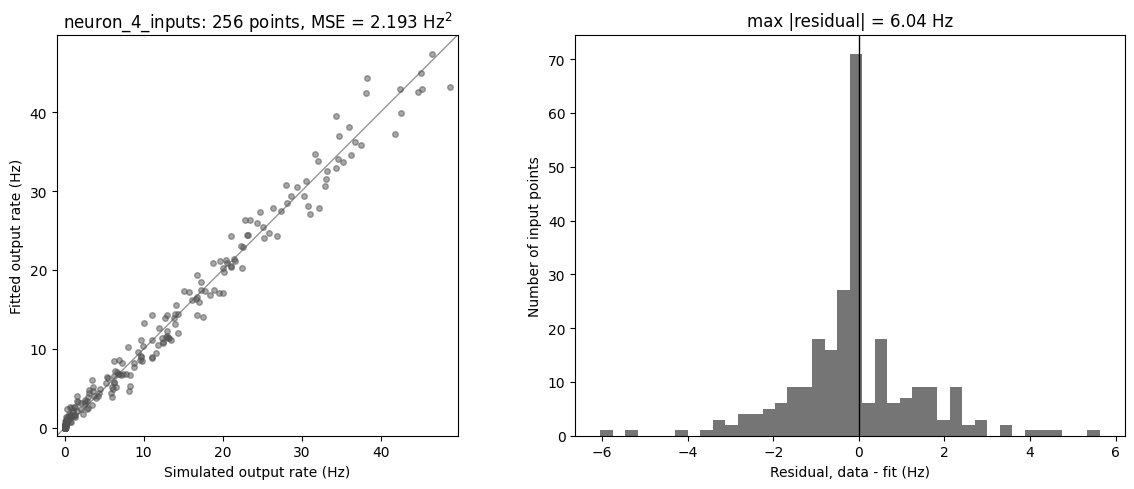

In [38]:
fig = plot_TF_fit_overview(df_data, neuron_model, mean_error)
figs.append(fig)

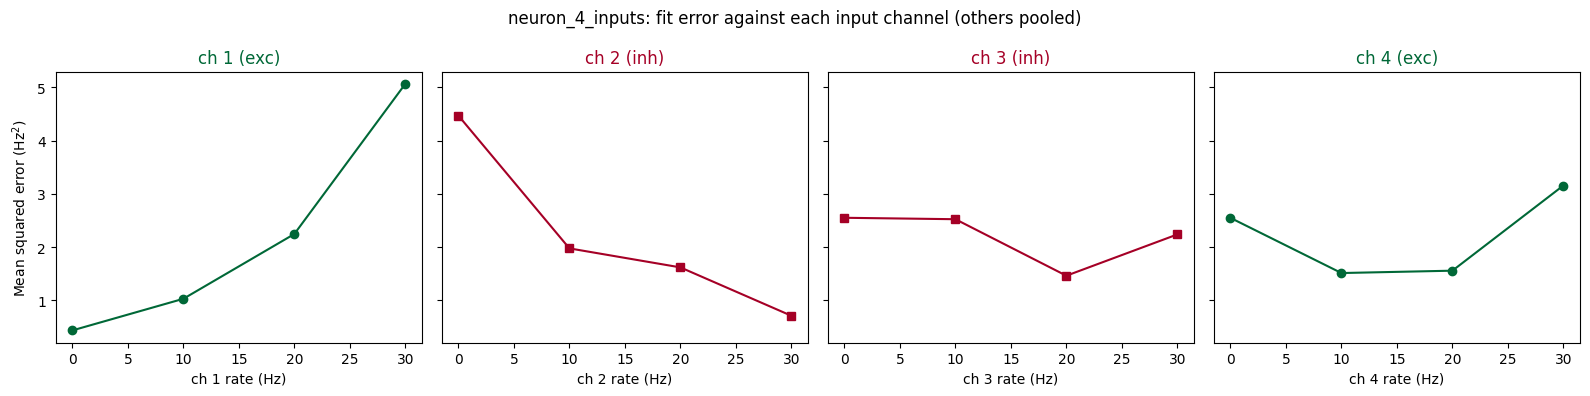

In [39]:
fig = plot_TF_fit_error_by_channel(df_data, ch_info, neuron_model)
figs.append(fig)

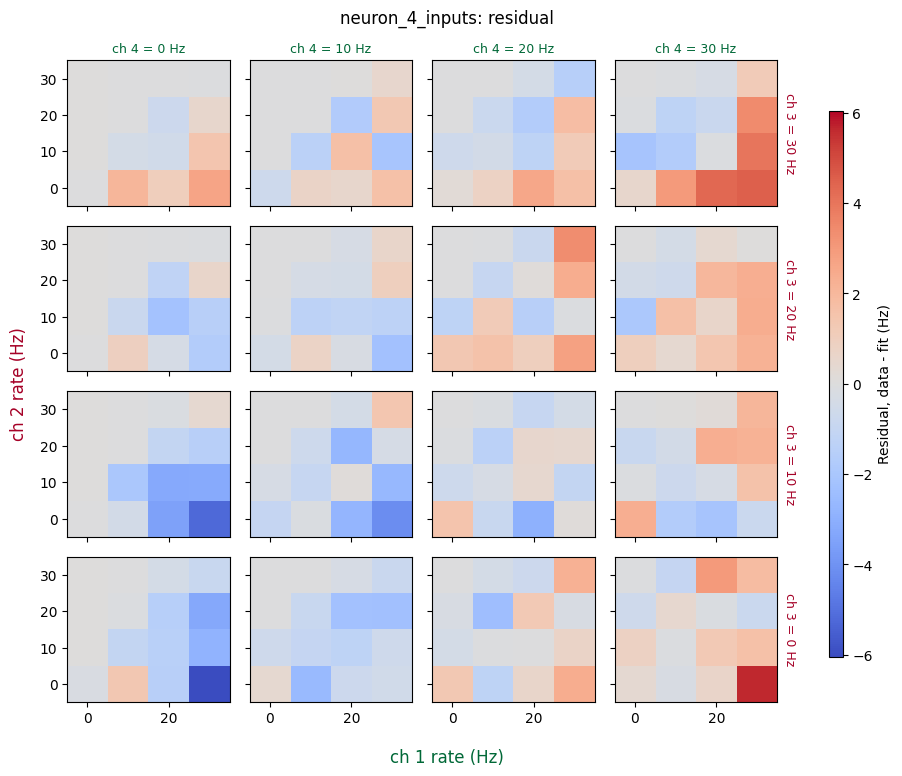

In [40]:
# Residuals (data - fit) over the whole input space, same layout as the data overview above
r_max = float(np.max(np.abs(df_data['residual'])))
fig = plot_TF_slice_grid(df_data, ch_info, neuron_model=neuron_model,
                         x_ch=x_ch, y_ch=y_ch,
                         row_ch=others[0] if len(others) > 0 else None,
                         col_ch=others[1] if len(others) > 1 else None,
                         fixed={k: fixed[k] for k in others[2:]},
                         value_col='residual', cmap='coolwarm', vmin=-r_max, vmax=r_max,
                         cbar_label='Residual, data - fit (Hz)')
figs.append(fig)

#### 2D slice (same plots as for RS/FS)

In [41]:
df_slice = tf_slice_as_ei(df_data, x_ch, y_ch, fixed)
x_s, y_s, df_std_slice_array = tf_grid_from_df(df_slice, value_col='std_f_out')

unique_inh = np.sort(df_slice['input_inh'].unique())
colors = cm.viridis(np.linspace(0, 1, len(unique_inh)))
slice_mean_error = res_2_func(poly_params_2, data=df_slice, params=params_SI, alpha=alpha)

def relabel(fig):
    # axis labels of the e/i plots -> channel labels of the slice
    ax = fig.axes[0]
    ax.set_xlabel(ch_info[x_ch]['label'])
    if ax.get_ylabel().startswith('Inhibitory'):
        ax.set_ylabel(ch_info[y_ch]['label'])
    ax.set_title(ax.get_title() + slice_suffix, fontsize=9)
    return fig

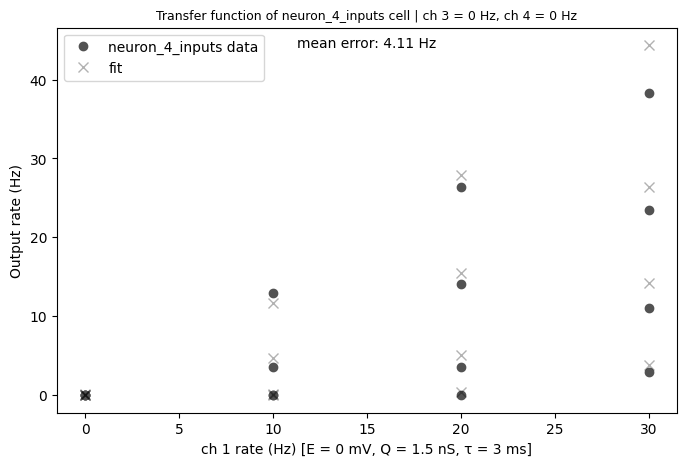

In [42]:
fig = relabel(plot_TF_fitting(neuron_model, df_slice, slice_mean_error))
figs.append(fig)

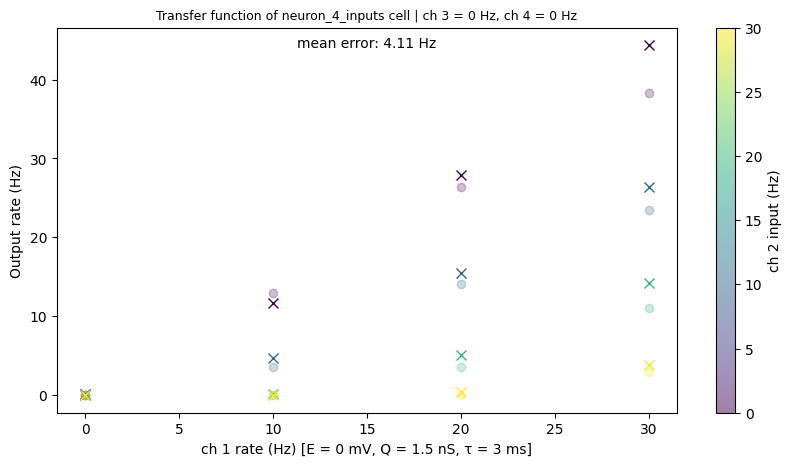

In [43]:
fig = relabel(plot_TF_fitting_viridis(neuron_model, df_slice, slice_mean_error, unique_inh, colors))
fig.axes[-1].set_ylabel(f'ch {y_ch} input (Hz)')
figs.append(fig)

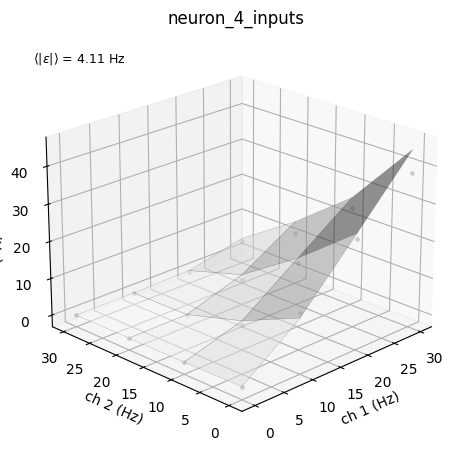

In [44]:
fig = mesh_3d_with_fitting(neuron_model, df_slice, mean_error=slice_mean_error)
fig.axes[0].set_xlabel(f'ch {x_ch} (Hz)'); fig.axes[0].set_ylabel(f'ch {y_ch} (Hz)')
figs.append(fig)

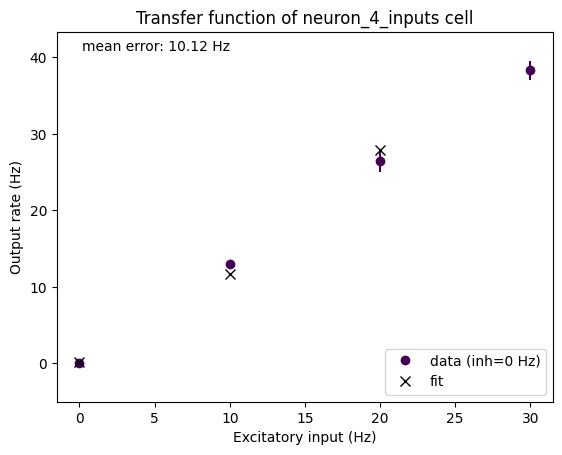

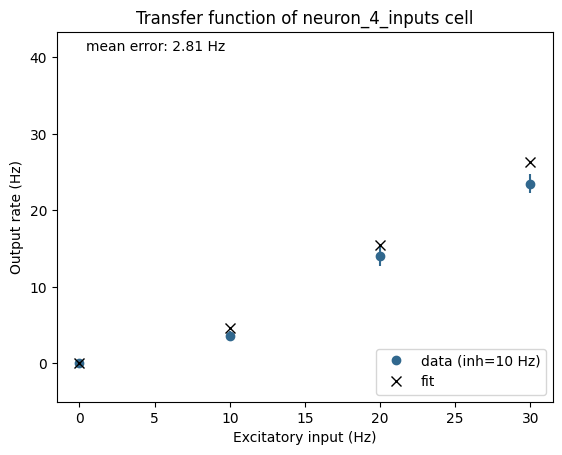

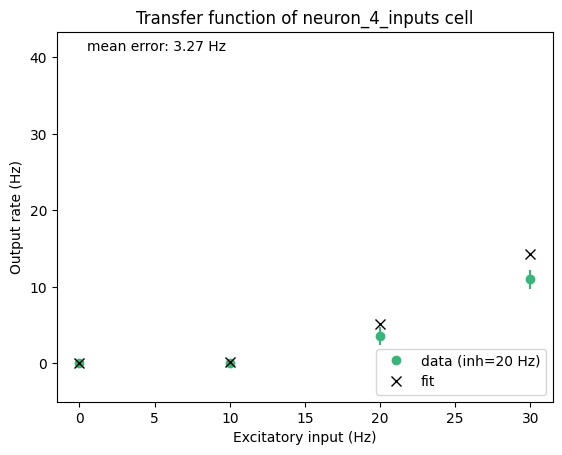

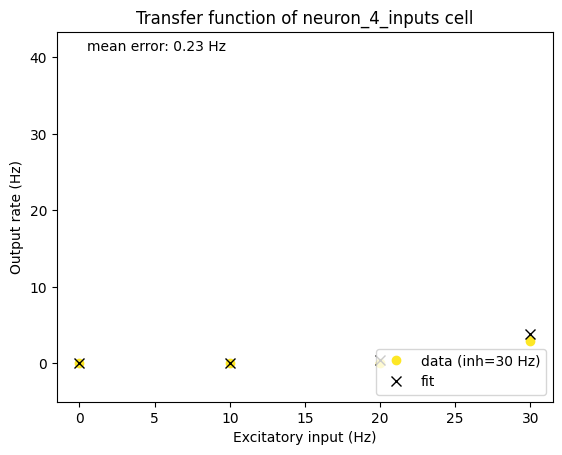

In [45]:
fig, distr_mean_error = plots_TF_fitting(neuron_model, df_slice, df_std_slice_array, poly_params_2, params_SI, alpha,
                                         unique_inh, colors, y_lim=(-5, df_slice['avg_f_out'].max() + 5))

In [46]:
if display_gif == True:
    from IPython.display import HTML, display
    import base64

    # --- 1) save the GIF to disk ---
    gif_path = make_TF_gif(
        neuron_model, df_slice, df_std_slice_array, poly_params_2, params_SI,
        alpha, unique_inh, colors,
        gif_name=gif_name,
        y_lim=(-5, df_slice['avg_f_out'].max() + 5))

    # --- 2) embed it inline so it animates in the notebook and is saved
    #        with it (survives reopening / sharing / re-runs) ---
    with open(gif_path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode("ascii")
    display(HTML(f'<img src="data:image/gif;base64,{b64}" alt="{neuron_model} TF fit">'))

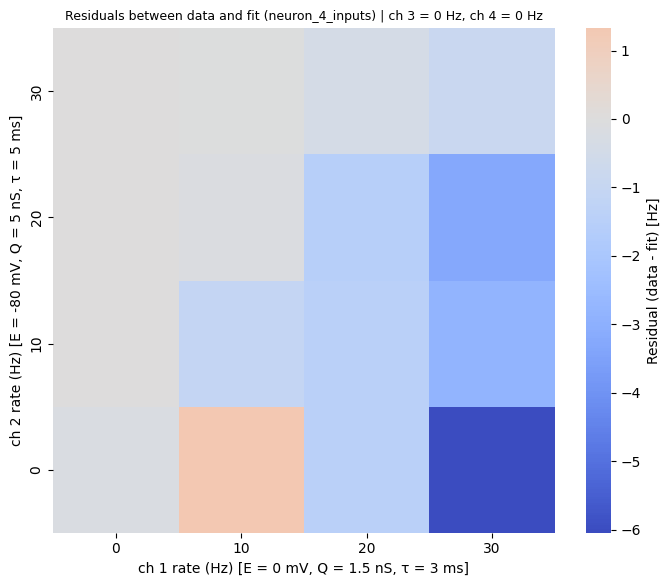

In [47]:
fig = relabel(plot_residuals_TF_fitting(neuron_model, df_slice))
figs.append(fig)

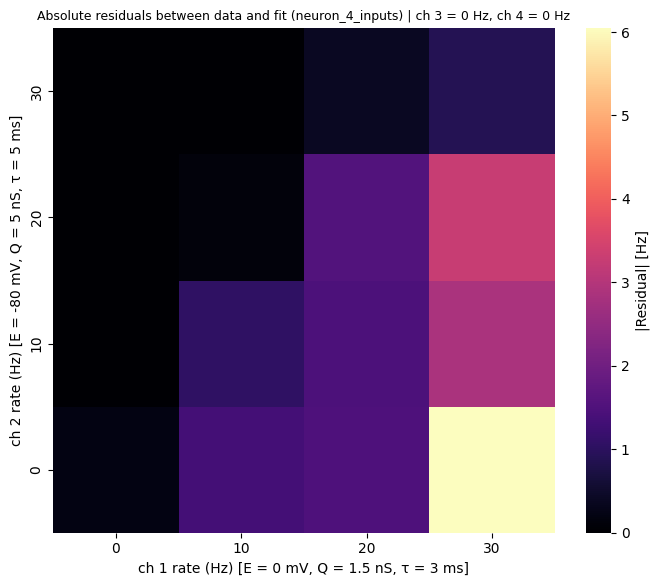

In [48]:
fig = relabel(plot_abs_residuals_TF_fitting(neuron_model, df_slice))
figs.append(fig)

In [49]:
save_figs(fig_path, fig_name + '_alpha_' + str(alpha) , figs)